# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [2]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('../data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [3]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: ['United States' 'China' 'India' 'Germany' 'United Kingdom' 'France'
 'Brazil' 'Japan' 'Canada' 'Australia' 'South Korea' 'Russia'
 'South Africa' 'Mexico' 'Indonesia']

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


---
## Task — Multi-Series Line Chart with Highlight

**What to build:** A line chart showing CO2 emissions over time for **all Asian countries** in the dataset, with one country highlighted.

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

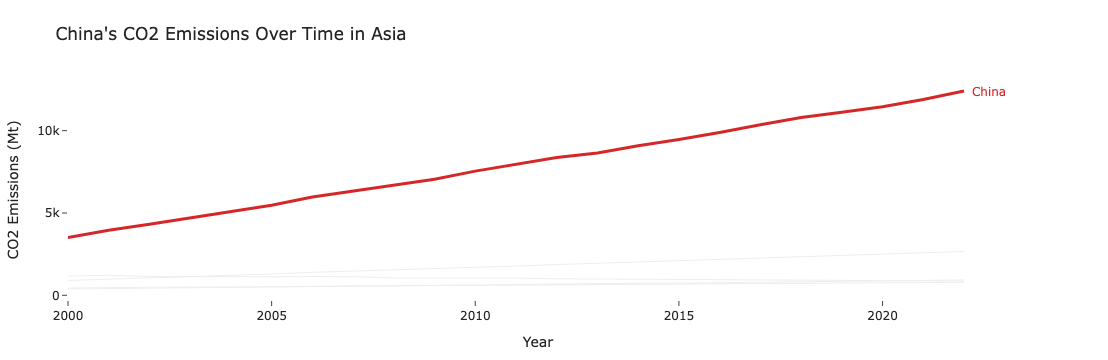

In [5]:
# Task — Multi-series line with highlight
# YOUR CODE HERE

# Select Asian countries
asia_df = df[df["Region"] == "Asia"].copy()

highlight_country = "China"

fig = go.Figure()

# Add each Asian country as a separate line
for country in asia_df["Country"].unique():
    country_df = asia_df[asia_df["Country"] == country]

    fig.add_trace(go.Scatter(
        x=country_df["Year"],
        y=country_df["CO2_Mt"],
        mode="lines",
        name=country
    ))

# Style all lines in grey first
fig.update_traces(
    line=dict(color="#EEEEEE", width=1),
    showlegend=False
)

# Highlight China using update_traces
fig.update_traces(
    selector=dict(name="China"),
    line=dict(color="#D62728", width=3)
)

# Label China at the end of its line
china_df = asia_df[asia_df["Country"] == "China"]
last_row = china_df.sort_values("Year").iloc[-1]

fig.add_annotation(
    x=last_row["Year"],
    y=last_row["CO2_Mt"],
    text="China",
    showarrow=False,
    xshift=25,
    font=dict(size=12, color="#D62728")
)

# Clean chart design
fig.update_layout(
    title="China's CO2 Emissions Over Time in Asia",
    xaxis_title="Year",
    yaxis_title="CO2 Emissions (Mt)",
    template="simple_white",
    showlegend=False,
    margin=dict(l=60, r=100, t=80, b=50)
)

fig.update_xaxes(showgrid=False, showline=False)
fig.update_yaxes(showgrid=False, showline=False)

fig.show()